# Pre-entrega 4 · Parte 2: K-Means base y elección de k

**Objetivo:** ajustar el modelo base de K-Means sobre las variables de juego por equipo-temporada (2000/01 a 2025/26), elegir la cantidad de clusters `k` con un criterio explícito y verificar que el resultado sea estable.

**Entradas** (generadas por `03_modelos_no_supervisados.ipynb`, Parte 1):
- `data/processed/features_clustering.csv` → 10 variables ya depuradas, con outliers recortados y escaladas con `StandardScaler`.
- `data/processed/tabla_equipo_temporada.csv` → misma cantidad de filas y mismo orden, con equipo, temporada, puntos, `top4` y `es_britanico` (solo para interpretar).

**Salidas** (para la Parte 3: mejora e interpretación):
- `data/processed/kmeans_base_metricas.csv` → métricas por cada k.
- `data/processed/clusters_kmeans_base.csv` → tabla equipo-temporada con el cluster asignado por el modelo base.

### Conceptos clave
| Concepto | Qué es | Cómo se lee |
|---|---|---|
| **K-Means** | Divide los datos en `k` grupos. Cada grupo tiene un centro (centroide) y cada punto se asigna al centroide más cercano (distancia euclídea). | — |
| **Inercia** | Suma de las distancias al cuadrado de cada punto a su centroide. | Más baja = grupos más compactos. Siempre baja al subir k, por eso se busca el "codo". |
| **Silhouette** | Para cada punto compara su distancia a su propio grupo vs. al grupo vecino más cercano. Va de -1 a 1. | Más alto = mejor. > 0,5 estructura fuerte; 0,25-0,5 débil/razonable; < 0,25 grupos poco separados. |
| **ARI** (Adjusted Rand Index) | Mide cuánto coinciden dos agrupamientos, corrigiendo por azar. | 1 = idénticos, 0 = coincidencia aleatoria. |

### Criterio para elegir k (definido ANTES de ver los resultados)
> **Se elige el k con mejor Silhouette, siempre que ningún cluster tenga menos del 5% de los datos. Si dos valores de k dan parecido, se elige el que se pueda interpretar como estilo de juego.**
>
> Para que "parecido" no quede a criterio libre lo fijamos como: **diferencia de Silhouette menor a 0,02** respecto del mejor k válido.

In [1]:
import os
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,         # cohesión vs. separación (más alto = mejor)
    adjusted_rand_score,      # coincidencia entre dos agrupamientos (para la estabilidad)
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})

# DECISIÓN: semilla fija.
# K-Means arranca con centroides elegidos al azar; fijar random_state hace que cada vez que
# alguien corra el notebook obtenga EXACTAMENTE los mismos clusters (reproducibilidad).
SEMILLA = 42

# DECISIÓN: rango de k entre 2 y 10.
# k=1 no tiene sentido (un solo grupo) y las métricas no se pueden calcular.
# Más de 10 grupos sobre ~520 filas daría clusters muy chicos e imposibles de interpretar como estilos.
RANGO_K = range(2, 11)   # range excluye el último valor -> 2, 3, ..., 10

# Umbrales del criterio (escritos como constantes para que se vean y se puedan citar)
MIN_PCT_CLUSTER = 5.0    # ningún cluster puede tener menos del 5% de las filas
TOL_SILHOUETTE = 0.02    # dos k son "parecidos" si su Silhouette difiere en menos de esto
N_SEMILLAS = 20          # corridas con semillas distintas para medir estabilidad

## 1. Carga de datos

In [2]:
DIR_DATOS = "../data/processed" if os.path.exists("../data/processed") else "data/processed"
ruta_features = os.path.join(DIR_DATOS, "features_clustering.csv")
ruta_tabla = os.path.join(DIR_DATOS, "tabla_equipo_temporada.csv")

if os.path.exists(ruta_features):
    X_df = pd.read_csv(ruta_features)
    tabla = pd.read_csv(ruta_tabla)
    USANDO_PRUEBA = False
else:
    # Respaldo: si todavía no se corrió la Parte 1, se usa un dataset sintético (make_blobs)
    # para poder probar el código.
    from sklearn.datasets import make_blobs
    X_sint, _ = make_blobs(n_samples=520, n_features=10, centers=4, random_state=SEMILLA)
    X_df = pd.DataFrame(X_sint, columns=[f"var_{i}" for i in range(10)])
    tabla = X_df.copy()
    USANDO_PRUEBA = True
    print("⚠ No se encontró features_clustering.csv: usando datos de PRUEBA (make_blobs).")
    print("  Corré primero notebooks/03_modelos_no_supervisados.ipynb")

# .values convierte el DataFrame a una matriz de numpy, que es lo que recibe scikit-learn.
X = X_df.values
print(f"Matriz de entrada: {X.shape[0]} filas x {X.shape[1]} variables")
print("Variables:", list(X_df.columns))

Matriz de entrada: 520 filas x 10 variables
Variables: ['tiros', 'goles_a_favor', 'corners', 'precision', 'conversion', 'goles_en_contra', 'tiros_en_contra', 'faltas', 'amarillas', 'rojas']


In [3]:
# Controles antes de modelar:
# 1) Sin valores faltantes: K-Means no acepta NaN.
# 2) Escalado correcto: media ~0 y desvío ~1 en todas las variables (StandardScaler).
#    Si no estuvieran escaladas, las variables con números grandes dominarían la distancia.
# 3) Mismo número de filas que la tabla de interpretación: así podemos pegar los clusters por posición.
assert X_df.isna().sum().sum() == 0, "Hay NaN en las features"
assert len(X_df) == len(tabla), "features y tabla no tienen la misma cantidad de filas"
X_df.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
tiros,-0.0,1.0,-1.98,2.61
goles_a_favor,0.0,1.0,-2.04,2.56
corners,-0.0,1.0,-2.19,2.69
precision,-0.0,1.0,-1.62,2.00
conversion,-0.0,1.0,-2.29,2.48
goles_en_contra,-0.0,1.0,-2.62,2.60
tiros_en_contra,0.0,1.0,-2.59,2.60
faltas,-0.0,1.0,-2.66,2.69
amarillas,0.0,1.0,-2.59,2.84
rojas,0.0,1.0,-1.57,3.23


## 2. K-Means base para k = 2 … 10

**Configuración del modelo base** (cada parámetro es una decisión):
- `init="k-means++"` → en vez de elegir los centroides iniciales totalmente al azar, los elige **separados entre sí**.
- `n_init=10` → corre el algoritmo 10 veces con distintos centroides iniciales y se queda con la de **menor inercia**. Reduce el riesgo de quedar en un mal óptimo local.
- `random_state=SEMILLA` → reproducibilidad.
- Se dejan por defecto `max_iter=300` (iteraciones máximas por corrida) y `algorithm="lloyd"` (el K-Means clásico).

In [4]:
resultados = []    # una fila de métricas por k
etiquetas = {}     # guardamos las etiquetas de cada k 

for k in RANGO_K:
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEMILLA)
    # fit_predict: ajusta el modelo y devuelve a qué cluster (0..k-1) pertenece cada fila.
    labels = modelo.fit_predict(X)
    etiquetas[k] = labels

    # np.bincount cuenta cuántas filas hay en cada cluster -> tamaño del cluster más chico en %.
    pct_min = np.bincount(labels).min() / len(labels) * 100

    resultados.append({
        "k": k,
        "inercia": modelo.inertia_,                            
        "silhouette": silhouette_score(X, labels),
        "pct_cluster_min": pct_min,
    })

metricas = pd.DataFrame(resultados).set_index("k")
metricas.round(3)

,inercia,silhouette,pct_cluster_min
k,,,
2,3792.271,0.257,31.154
3,3017.960,0.241,25.385
4,2752.210,0.223,14.038
5,2528.472,0.202,9.231
6,2356.931,0.175,9.231
7,2243.554,0.165,9.423
8,2148.065,0.157,9.423
9,2056.827,0.160,6.731
10,1984.336,0.154,6.731


### Gráficos de las métricas
El método del codo busca el punto donde la inercia deja de bajar fuerte: agregar más clusters a partir de ahí aporta poco. El Silhouette se lee buscando el máximo.

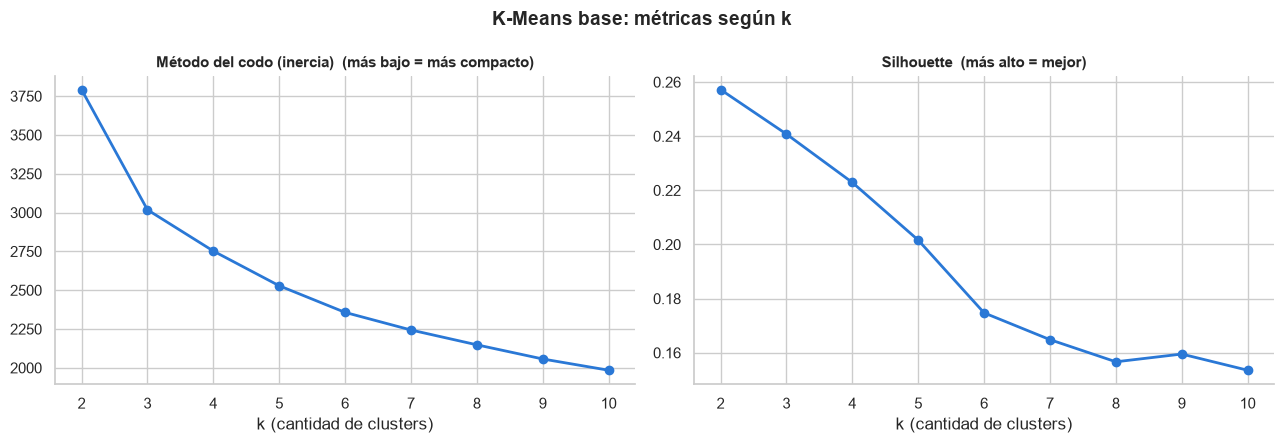

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
graficos = [
    ("inercia", "Método del codo (inercia)", "más bajo = más compacto"),
    ("silhouette", "Silhouette", "más alto = mejor"),
]
for ax, (col, titulo, lectura) in zip(axes.flat, graficos):
    ax.plot(metricas.index, metricas[col], marker="o", color="#2a78d6", linewidth=2)
    ax.set_title(f"{titulo}  ({lectura})", fontsize=11)
    ax.set_xlabel("k (cantidad de clusters)")
    ax.set_xticks(list(RANGO_K))
plt.suptitle("K-Means base: métricas según k", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

## 3. Aplicación del criterio de elección de k

In [6]:
# Paso 1: descartar los k que tengan algún cluster con menos del 5% de los datos.
# Un cluster tan chico no representa un "estilo" sino unos pocos casos raros.
metricas["cumple_5pct"] = metricas["pct_cluster_min"] >= MIN_PCT_CLUSTER
validos = metricas[metricas["cumple_5pct"]]

# Paso 2: entre los válidos, el de mayor Silhouette.
# idxmax devuelve el índice (el k) donde la columna es máxima.
k_mejor_sil = validos["silhouette"].idxmax()
sil_max = validos.loc[k_mejor_sil, "silhouette"]

# Paso 3: candidatos "parecidos" = Silhouette a menos de 0,02 del mejor.
candidatos = validos[sil_max - validos["silhouette"] < TOL_SILHOUETTE]

print(f"k válidos (ningún cluster < {MIN_PCT_CLUSTER}%): {list(validos.index)}")
print(f"Mejor Silhouette: k = {k_mejor_sil} (silhouette = {sil_max:.3f})")
print(f"Candidatos parecidos (diferencia < {TOL_SILHOUETTE}): {list(candidatos.index)}")
candidatos.round(3)

k válidos (ningún cluster < 5.0%): [2, 3, 4, 5, 6, 7, 8, 9, 10]
Mejor Silhouette: k = 2 (silhouette = 0.257)
Candidatos parecidos (diferencia < 0.02): [2, 3]


,inercia,silhouette,pct_cluster_min,cumple_5pct
k,,,,
2,3792.271,0.257,31.154,True
3,3017.960,0.241,25.385,True


Como hay más de un candidato, el criterio dice que hay que desempatar por **interpretabilidad como estilo de juego**. Para eso comparamos los perfiles de los candidatos: el promedio de cada variable (escalada) dentro de cada cluster.

Lectura del heatmap: valores positivos = el cluster está por encima del promedio de la liga en esa variable; negativos = por debajo. Las últimas columnas (`puntos`, `top4`, `año promedio`) **no se usaron para formar los clusters**, se agregan solo para interpretar.

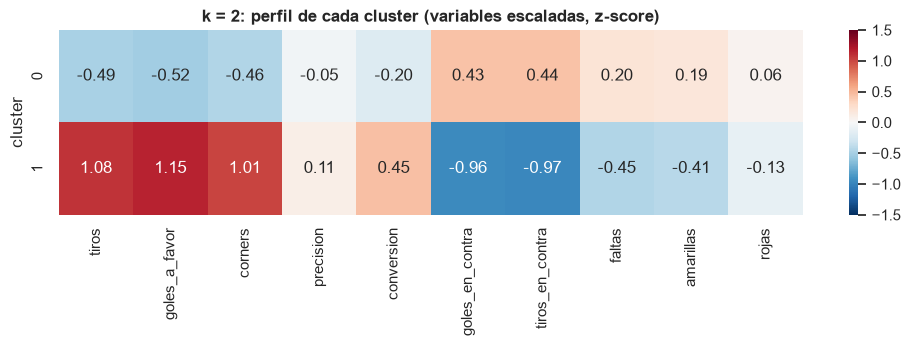

,puntos,top4,anio_promedio,n_equipos
cluster,,,,
0,42.91,0.01,2012.34,358
1,71.52,0.63,2012.86,162


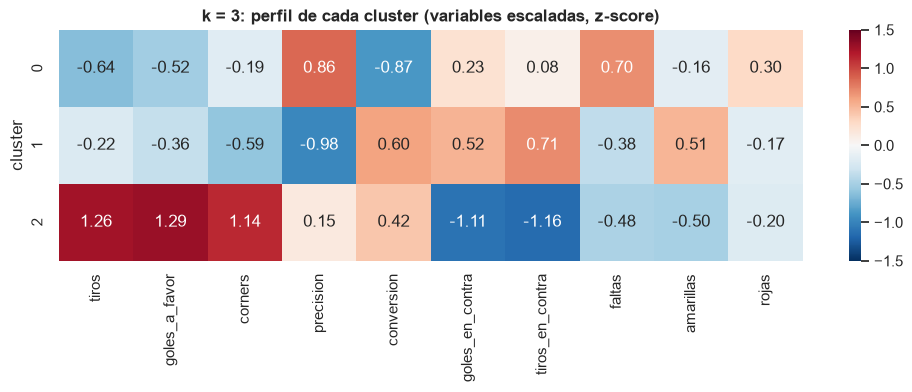

,puntos,top4,anio_promedio,n_equipos
cluster,,,,
0,43.79,0.01,2005.97,196
1,44.57,0.02,2019.20,192
2,74.31,0.74,2012.45,132


In [7]:
def perfil(k):
    # Promedio de cada variable escalada por cluster + variables de contexto (sin escalar).
    p = X_df.groupby(etiquetas[k]).mean()
    contexto = tabla.groupby(etiquetas[k]).agg(
        puntos=("puntos", "mean"), top4=("top4", "mean"), anio_promedio=("temp_inicio", "mean"))
    p.index.name = "cluster"
    contexto.index.name = "cluster"
    return p, contexto

if not USANDO_PRUEBA:
    for k in candidatos.index:
        p, contexto = perfil(k)
        fig, ax = plt.subplots(figsize=(12, 1.2 + 0.6 * k))
        sns.heatmap(p, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, ax=ax)
        ax.set_title(f"k = {k}: perfil de cada cluster (variables escaladas, z-score)")
        plt.show()
        display(contexto.assign(n_equipos=pd.Series(etiquetas[k]).value_counts().sort_index()).round(2))

### ¿El cluster extra de k=3 es un estilo de juego o un efecto de la medición?
Con k=3 aparecen dos clusters de equipos "no élite" que se diferencian sobre todo en `precision` (tiros al arco / tiros) y en el año promedio. En la Parte 1 se detectó que **desde 2013/14 cambió el criterio con el que football-data registra los tiros al arco**. Si el cluster extra solo separa "antes vs. después de 2013",es un artefacto de los datos. Lo verificamos con una tabla cruzada:

In [8]:
if not USANDO_PRUEBA:
    era = np.where(tabla["temp_inicio"] >= 2013, "2013/14 en adelante", "hasta 2012/13")
    # pd.crosstab cuenta cuántas filas hay en cada combinación (cluster x época).
    # normalize="index" -> porcentaje por fila (cada cluster suma 100%).
    for k in candidatos.index:
        print(f"k = {k}: % de equipos de cada época dentro de cada cluster")
        display((pd.crosstab(etiquetas[k], era, normalize="index", rownames=["cluster"], colnames=["época"]) * 100).round(1))

k = 2: % de equipos de cada época dentro de cada cluster


época,2013/14 en adelante,hasta 2012/13
cluster,,
0,48.3,51.7
1,53.7,46.3


k = 3: % de equipos de cada época dentro de cada cluster


época,2013/14 en adelante,hasta 2012/13
cluster,,
0,0.5,99.5
1,99.5,0.5
2,51.5,48.5


## 4. Estabilidad: 20 semillas distintas + ARI

**Cómo:** para cada k corremos el modelo base 20 veces (`random_state` = 0…19, con la misma configuración `k-means++` y `n_init=10`) y comparamos **todos los pares** de resultados con el ARI (20 corridas → 190 pares).

¿Por qué ARI y no "porcentaje de coincidencia"? Porque los números de cluster son arbitrarios: el "cluster 0" de una corrida puede ser el "cluster 2" de otra. El ARI compara **qué filas quedan juntas**, sin importar el número que tenga cada grupo.

**Criterio de lectura**: ARI medio ≥ 0,90 → estable; entre 0,75 y 0,90 → moderado; < 0,75 → no confiable.

In [9]:
estabilidad = {}
for k in RANGO_K:
    corridas = [KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=s).fit_predict(X)
                for s in range(N_SEMILLAS)]
    # itertools.combinations(lista, 2) genera todos los pares posibles sin repetir: (0,1), (0,2), ...
    aris = [adjusted_rand_score(a, b) for a, b in itertools.combinations(corridas, 2)]
    estabilidad[k] = {"ari_medio": np.mean(aris), "ari_minimo": np.min(aris)}

metricas = metricas.join(pd.DataFrame(estabilidad).T)
metricas["estabilidad"] = pd.cut(metricas["ari_medio"], bins=[-1, 0.75, 0.90, 1.01],
                                 labels=["no confiable", "moderada", "estable"])
metricas[["silhouette", "pct_cluster_min", "ari_medio", "ari_minimo", "estabilidad"]].round(3)

,silhouette,pct_cluster_min,ari_medio,ari_minimo,estabilidad
k,,,,,
2,0.257,31.154,0.998,0.992,estable
3,0.241,25.385,1.000,1.000,estable
4,0.223,14.038,0.986,0.953,estable
5,0.202,9.231,0.983,0.932,estable
6,0.175,9.231,0.929,0.847,estable
7,0.165,9.423,0.844,0.639,moderada
8,0.157,9.423,0.719,0.502,no confiable
9,0.160,6.731,0.671,0.464,no confiable
10,0.154,6.731,0.662,0.455,no confiable


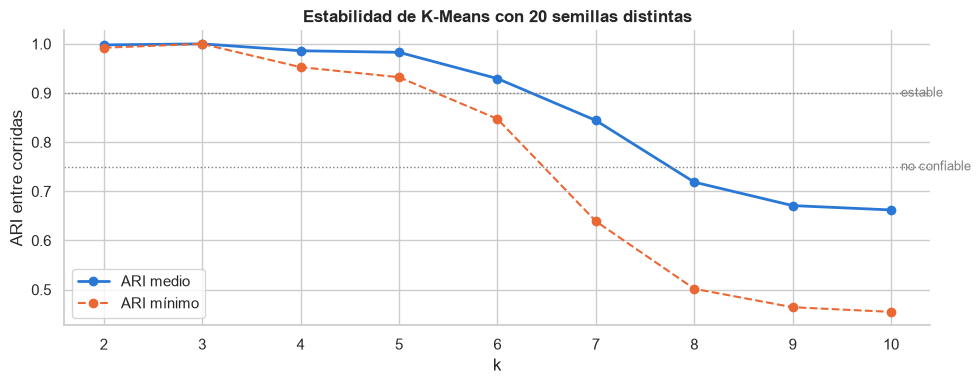

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(metricas.index, metricas["ari_medio"], marker="o", color="#2a78d6", linewidth=2, label="ARI medio")
ax.plot(metricas.index, metricas["ari_minimo"], marker="o", color="#eb6834", linestyle="--", label="ARI mínimo")
ax.axhline(0.90, color="grey", linestyle=":", linewidth=1)
ax.axhline(0.75, color="grey", linestyle=":", linewidth=1)
ax.text(10.1, 0.90, "estable", va="center", fontsize=9, color="grey")
ax.text(10.1, 0.75, "no confiable", va="center", fontsize=9, color="grey")
ax.set_xticks(list(RANGO_K))
ax.set_xlabel("k")
ax.set_ylabel("ARI entre corridas")
ax.set_title(f"Estabilidad de K-Means con {N_SEMILLAS} semillas distintas")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 5. Modelo base final y archivos para la Parte 3

In [11]:
K_ELEGIDO = 2

modelo_base = KMeans(n_clusters=K_ELEGIDO, init="k-means++", n_init=10, random_state=SEMILLA).fit(X)

tabla_clusters = tabla.copy()
tabla_clusters["cluster_base"] = modelo_base.labels_

print(f"k elegido: {K_ELEGIDO}")
print("Tamaño de cada cluster:")
print(tabla_clusters["cluster_base"].value_counts().sort_index())
display(metricas.loc[[K_ELEGIDO]].round(3))

if not USANDO_PRUEBA:
    metricas.round(4).to_csv(os.path.join(DIR_DATOS, "kmeans_base_metricas.csv"))
    tabla_clusters.to_csv(os.path.join(DIR_DATOS, "clusters_kmeans_base.csv"), index=False)
    print(f"\n✓ Guardado: {DIR_DATOS}/kmeans_base_metricas.csv")
    print(f"✓ Guardado: {DIR_DATOS}/clusters_kmeans_base.csv")

k elegido: 2
Tamaño de cada cluster:
cluster_base
0    358
1    162
Name: count, dtype: int64


,inercia,silhouette,pct_cluster_min,cumple_5pct,ari_medio,ari_minimo,estabilidad
k,,,,,,,
2,3792.271,0.257,31.154,True,0.998,0.992,estable



✓ Guardado: ../data/processed/kmeans_base_metricas.csv
✓ Guardado: ../data/processed/clusters_kmeans_base.csv


## 6. Conclusión: decisión y criterio

| Paso del criterio | Resultado |
|---|---|
| ¿Algún cluster < 5%? | Ningún k entre 2 y 10 lo incumple (el cluster más chico nunca baja del 6,7%). Todos son válidos. |
| Mejor Silhouette | **k = 2** (0,257). |
| ¿Hay otro k parecido (< 0,02)? | Sí: **k = 3** (0,241, diferencia 0,016). |
| Desempate por interpretabilidad | Con k=3 el cluster extra parte a los equipos "no élite" en **antes vs. después de 2013/14** (uno de los clusters tiene 99,5% de equipos hasta 2012/13 y el otro 99,5% desde 2013/14) y se diferencia sobre todo en `precision`. Eso refleja el **cambio de criterio de medición de los tiros al arco**, no un estilo de juego. |
| Estabilidad | k=2 y k=3 son muy estables (ARI medio ≈ 1). A partir de k=7 la estabilidad cae (ARI < 0,85) y desde k=8 no es confiable. |

**Decisión: k = 2.** Tiene el mejor Silhouette, cumple el tamaño mínimo, es totalmente estable y sus dos grupos son interpretables: un grupo **"dominante"** (más tiros, goles y córners, menos goles y tiros en contra, menos faltas y tarjetas; ~72 puntos y 63% de Top 4) y un grupo **"resto de la liga"** (~43 puntos, casi sin Top 4).

**Limitaciones (para la Parte 3):**
- Con k=2 el modelo separa sobre todo **nivel** (buenos vs. resto) más que **estilo**.